# Bassez et al. 2021 — Breast Cancer (10x)
## 02 · Manifold — scFates topology, root, pseudotime

Test topology honestly (PPT tree vs curve), match the scFates method to the topology, root at the Gast/pSom-high developmental origin, and compute pseudotime. Continuity is judged off the **fitted graph** (fold self-approach ratio), not off a re-embedding.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold + re-score modules
Re-score modules and graph-smooth (for the origin axis and gradients); raw means are the honest readout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 65464 cells
UMAP principal-axis ratio (major/minor singular value): 1.11
raw module means (honest readout): {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.0051}


### Honest branching test — PPT tree node geography
A genuine bifurcation requires a Gast-enriched arm **opposing** a pSom-enriched arm out of a shared hub. Fit a PPT tree at several stiffnesses; for each, report the extreme tips' module means and the **node-cluster** Gast/pSom/Crest correlations. If no tip is Gast-high (Gast arm absent) and Crest~pSom is strongly negative, the forks are lobe over-fitting of a single (pSom -> Crest) axis, not a bifurcation -> fit a curve.

In [4]:
def node_means(a):
    B = np.asarray(a.uns['graph']['B']); R = np.asarray(a.obsm['X_R']); hard = R.argmax(1)
    df = pd.DataFrame({m:[a.obs[m+'_sm'][hard==k].mean() for k in range(B.shape[0])] for m in ['Gast','pSom','Crest']})
    df['n'] = [int((hard==k).sum()) for k in range(B.shape[0])]
    tip = np.where((B>0).sum(0)==1)[0]; fork = np.where((B>0).sum(0)>=3)[0]
    return df, tip, fork
for lam in [1000, 2000, 5000]:
    a = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a, Nodes=100, use_rep='X_umap', method='ppt', ppt_lambda=lam, ppt_sigma=0.5, seed=SEED, plot=False)
    df, tip, fork = node_means(a); nd = df.dropna()
    r_gp = np.corrcoef(nd.Gast, nd.pSom)[0,1]; r_cp = np.corrcoef(nd.Crest, nd.pSom)[0,1]; r_cg = np.corrcoef(nd.Crest, nd.Gast)[0,1]
    tp = df.loc[tip].dropna()
    print(f'PPT tree Nodes=100 lambda={lam}: {len(tip)} tips, {len(fork)} forks | '
          f'max tip Gast={tp.Gast.max():+.3f} (Gast arm absent if <=0), max tip pSom={tp.pSom.max():+.3f} | '
          f'node corr Gast~pSom={r_gp:+.2f} Crest~pSom={r_cp:+.2f} Crest~Gast={r_cg:+.2f}')
print('-> no Gast-enriched arm at any stiffness; forks are lobe over-fitting of a single pSom->Crest axis, not a bifurcation.')

PPT tree Nodes=100 lambda=1000: 11 tips, 9 forks | max tip Gast=-0.001 (Gast arm absent if <=0), max tip pSom=+0.050 | node corr Gast~pSom=-0.23 Crest~pSom=-0.84 Crest~Gast=-0.24
PPT tree Nodes=100 lambda=2000: 9 tips, 7 forks | max tip Gast=-0.001 (Gast arm absent if <=0), max tip pSom=+0.050 | node corr Gast~pSom=-0.14 Crest~pSom=-0.87 Crest~Gast=-0.28
PPT tree Nodes=100 lambda=5000: 8 tips, 6 forks | max tip Gast=-0.002 (Gast arm absent if <=0), max tip pSom=+0.052 | node corr Gast~pSom=-0.08 Crest~pSom=-0.89 Crest~Gast=-0.31
-> no Gast-enriched arm at any stiffness; forks are lobe over-fitting of a single pSom->Crest axis, not a bifurcation.


### Fit the curve (non-branching) + fold check
scFates `curve` over a node sweep: 2 tips / 0 forks across settings confirms a non-branching topology. **Fold self-approach ratio** = (min Euclidean distance between graph-distant nodes) / (median edge length), computed on the fitted graph itself — independent of the UMAP neighbour structure; > 1 = fold-free.

In [5]:
def fold_diag(a):
    B = np.asarray(a.uns['graph']['B']); F = a.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for x in range(F.shape[0]):
        for y in range(x+1, F.shape[0]):
            if G[x,y] >= 3: dmin = min(dmin, np.sqrt(((F[x]-F[y])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15, 20, 30]:
    a = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.76
curve N=20: 2 tips, 0 forks | self-approach 2.43
curve N=30: 2 tips, 0 forks | self-approach 2.05
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.43 (>1 = fold-free)


### Root from developmental order
Gast/pSom is EARLY, Crest is LATE. Compare the two curve tips by (Gast+pSom-Crest); root at the Gast/pSom-high, Crest-low tip. Then verify the pseudotime gradients and that the axis is not proliferation-driven.

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for smod in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[smod]); print(f'  {smod}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s, g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (secondary; axis is not proliferation-driven)')

tip 0: Gast=-0.0152 pSom=+0.0121 Crest=+0.0048
tip 2: Gast=-0.0155 pSom=+0.0228 Crest=-0.0032
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.099 p=1.7e-143
  pSom_sm: rho=-0.282 p=0.0e+00
  Crest_sm: rho=+0.284 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.40
Somitogenesis-high decile mean pseudotime = 0.42
Gastrulation-high decile mean pseudotime = 0.23
caveat: pseudotime vs cycling score rho = +0.17 (secondary; axis is not proliferation-driven)


### House orientation consistent with pseudotime

In [7]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin on left, terminus on right)')
assert r > 0.3, f'orientation not pseudotime-consistent (corr={r:.2f})'

corr(x_lin, pseudotime) = +0.88 (origin on left, terminus on right)


### Save manifold.h5ad + manifold.pdf (pseudotime)

saved manifold.h5ad + manifold.pdf


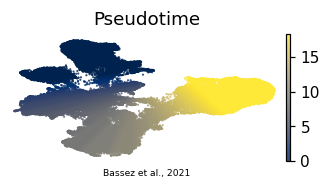

In [8]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=8, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')